# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

Name : Vaishnavi Goyal

Srn : PES2UG24CS571

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [3]:
# TODO 1: one 1080p RGB frame, in MB
# 1920 * 1080 pixels * 3 channels * 1 byte/channel
frame_mb = (1920 * 1080 * 3) / (1024 ** 2)

# TODO 2: frames per camera per day at 30 fps
# 24 h * 3600 s/h * 30 fps
frames_per_day = 24 * 3600 * 30

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
# total bytes = 400 cameras * frames_per_day * frame_size_in_bytes
bytes_per_day_fleet = 400 * frames_per_day * (1920 * 1080 * 3)
fleet_tb = bytes_per_day_fleet / (1024 ** 4)

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
frame_size_small_bytes = 640 * 360 * 3
frames_per_day_small = 24 * 3600 * 10
bytes_per_day_fleet_small = 400 * frames_per_day_small * frame_size_small_bytes
fleet_tb_small = bytes_per_day_fleet_small / (1024 ** 4)

pct_pixels_remaining = ((640 * 360) / (1920 * 1080)) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_
* **One spatial piece of evidence:** Downsampling from 1080p to 360p removes 88.89% of the pixels per frame. High-frequency spatial details such as license plates, facial features, or tiny distinct items on a suspect would be permanently blurred out due to spatial raster interpolation limitations, rendering them unidentifiable.
* **One temporal piece of evidence:** Dropping the frame rate from 30 fps to 10 fps increases the time step between consecutive frames from 33.3 ms to 100 ms. Fast actions (such as a muzzle flash, the exact moment of glass breaking, or a thrown object) could occur completely within these 100 ms gaps and be completely missed. Moreover, it worsens the "correspondence problem" (temporal aliasing), making tracking fast-moving targets extremely difficult.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

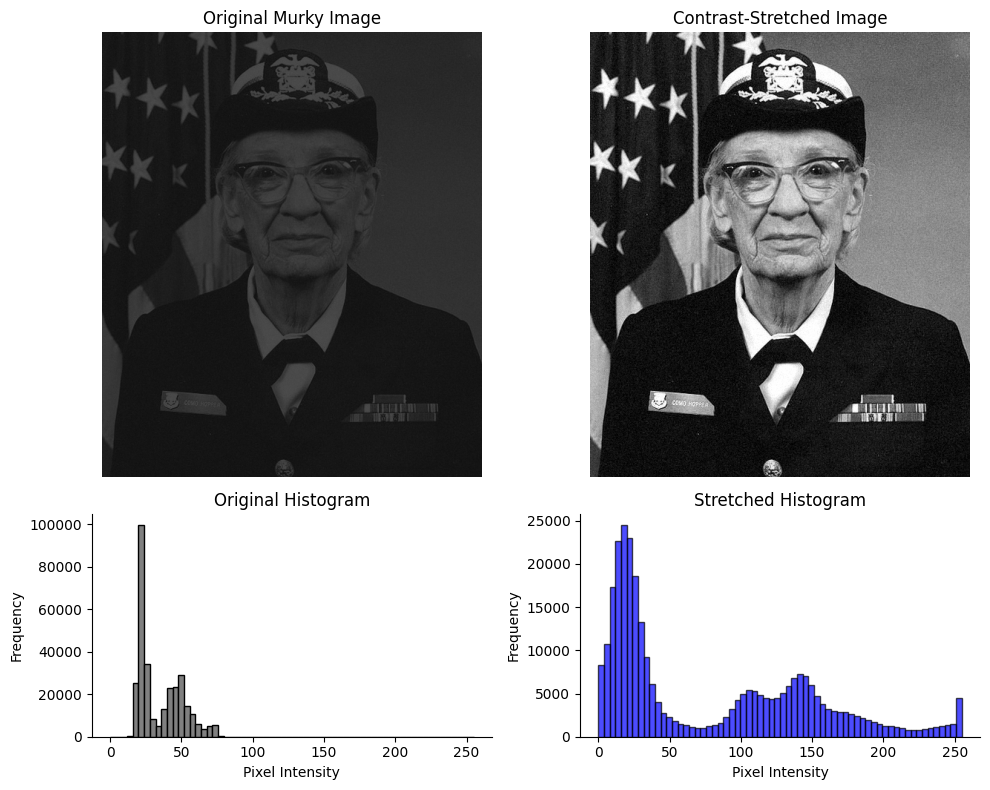

Contrast before: 0.609  ->  after: 1.000


In [4]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still (using 1st and 99th percentiles)
lmin = np.percentile(night_still, 1)
lmax = np.percentile(night_still, 99)
c_before = michelson(lmax, lmin)

# TODO 3: contrast-stretched version of night_still
stretched = 255.0 * (night_still - lmin) / (lmax - lmin)
stretched = np.clip(stretched, 0, 255)

lmin_stretched = np.percentile(stretched, 1)
lmax_stretched = np.percentile(stretched, 99)
c_after = michelson(lmax_stretched, lmin_stretched)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})

# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
# Before
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Murky Image")
axes[0, 0].axis("off")

axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="gray", edgecolor="black")
axes[1, 0].set_title("Original Histogram")
axes[1, 0].set_xlabel("Pixel Intensity")
axes[1, 0].set_ylabel("Frequency")

# After
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast-Stretched Image")
axes[0, 1].axis("off")

axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="blue", edgecolor="black", alpha=0.7)
axes[1, 1].set_title("Stretched Histogram")
axes[1, 1].set_xlabel("Pixel Intensity")
axes[1, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_
* **Shape description:** The original histogram is **unimodal and extremely narrow (low contrast)**, concentrated entirely in a tiny band of low-intensity dark values (around 15 to 45).
* **Stretching explanation:** Contrast stretching remaps the narrow range of values to fill the dynamic range of 0 to 255. While it adds no new information (the original spatial structure is unchanged), it spreads out the bin values so that human eyes (and computer vision systems) can easily distinguish subtle luminance variations that were previously too compressed and dim to see.
* **Why histogram alone is insufficient:** A histogram is a global 1D statistical summary of pixel frequency distributions. It completely discards spatial arrangement (where each pixel is located). Different spatial structures can share the identical pixel distribution, proving that "Same Histogram ≠ Same Image".

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing intervals:
  First detected standing: 68.70 s, Last: 78.10 s
Running intervals:
  First detected running: 78.60 s, Last: 86.00 s


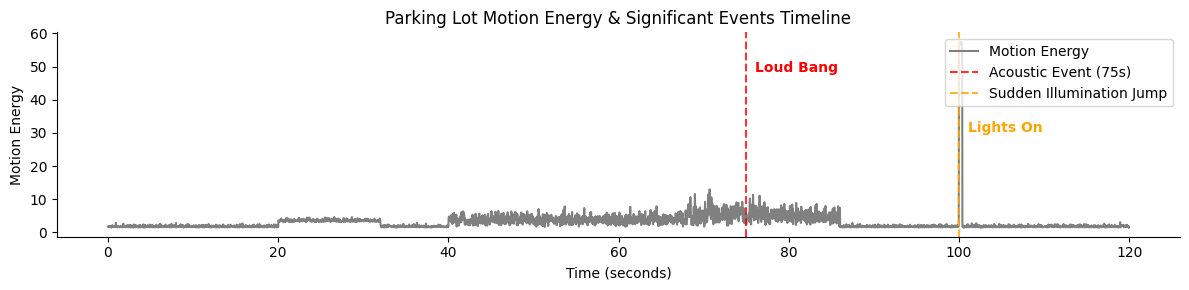

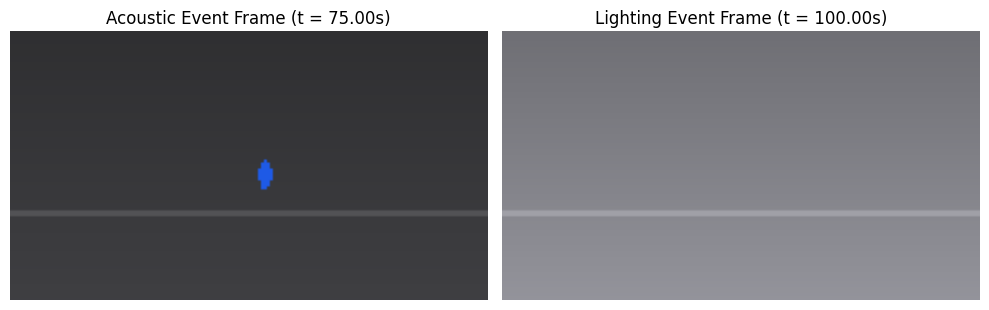

In [5]:
# TODO 1: person speed (px/s)
# dx and dy over a 30-frame window (1 second window)
dx = cctv["person_x"].diff(periods=30)
dy = cctv["person_y"].diff(periods=30)
# dt is 1.0 second since period is 30 frames at 30 fps
speed = np.sqrt(dx**2 + dy**2) / 1.0

# TODO 2: standing / running time ranges (print the first and last time of each)
standing_mask = speed < 3
running_mask = speed > 25

standing_times = cctv.loc[standing_mask, "time_s"]
running_times = cctv.loc[running_mask, "time_s"]

print("Standing intervals:")
if len(standing_times) > 0:
    print(f"  First detected standing: {standing_times.iloc[0]:.2f} s, Last: {standing_times.iloc[-1]:.2f} s")
print("Running intervals:")
if len(running_times) > 0:
    print(f"  First detected running: {running_times.iloc[0]:.2f} s, Last: {running_times.iloc[-1]:.2f} s")

# TODO 3: event frame indices
audio_event_idx = cctv[cctv["audio_level_db"] > -20].index[0]

# Find lighting event where mean_brightness jumps by more than 40 in one frame
lighting_event_idx = cctv[cctv["mean_brightness"].diff() > 40].index[0]

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv["time_s"], cctv["motion_energy"], color="gray", label="Motion Energy")

# Add markers
t_audio_event = cctv.loc[audio_event_idx, "time_s"]
t_light_event = cctv.loc[lighting_event_idx, "time_s"]

ax.axvline(t_audio_event, color="red", linestyle="--", alpha=0.8, label="Acoustic Event (75s)")
ax.text(t_audio_event + 1, ax.get_ylim()[1] * 0.8, "Loud Bang", color="red", fontweight="bold")

ax.axvline(t_light_event, color="orange", linestyle="--", alpha=0.8, label="Sudden Illumination Jump")
ax.text(t_light_event + 1, ax.get_ylim()[1] * 0.5, "Lights On", color="orange", fontweight="bold")

ax.set_title("Parking Lot Motion Energy & Significant Events Timeline")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Motion Energy")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

# TODO 5: one keyframe per event
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.imshow(render_frame(cctv.iloc[audio_event_idx]))
ax1.set_title(f"Acoustic Event Frame (t = {t_audio_event:.2f}s)")
ax1.axis("off")

ax2.imshow(render_frame(cctv.iloc[lighting_event_idx]))
ax2.set_title(f"Lighting Event Frame (t = {t_light_event:.2f}s)")
ax2.axis("off")
plt.tight_layout()
plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_
* **Missed events and reason:** Both of our significant events—the acoustic bang event around t = 75.0 s and the sudden lightning illumination event around t = 100.0 s—could have been easily missed or poorly captured. A rigid 20 s uniform keyframing strategy would capture frames at precisely t = 0, 20, 40, 60, 80, 100, 120 s. The exact frame corresponding to the transient loud bang event at t = 75 s would be entirely missed since it falls in the gap between the 60 s and 80 s keyframes. The event is extremely localized in time, making uniform sampling completely blind to transient anomalies.
* **Lecture concept:** The approach we used instead is called **content-based keyframe extraction (or event-driven / activity-based keyframe selection)**. Rather than sampling uniformly at arbitrary time increments, it dynamically selects representative frames based on feature changes or threshold anomalies (such as peaks in audio levels, changes in motion vectors, or rapid jumps in frame illumination).

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

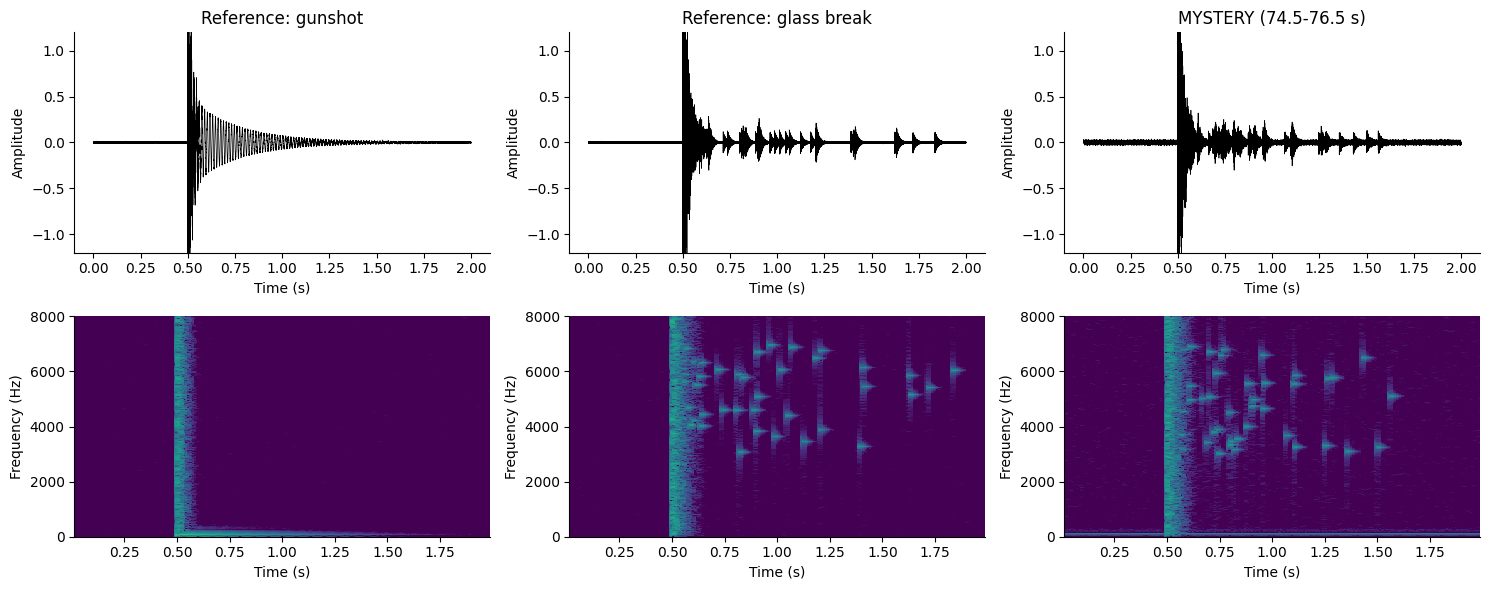

{'Reference: gunshot': np.float64(0.0030352610136762824), 'Reference: glass break': np.float64(0.9891874044148661), 'MYSTERY (74.5-76.5 s)': np.float64(0.8734552491106999)}
Verdict: The mystery audio clip matches a GLASS BREAK signature due to its high-frequency energy ratio.


In [6]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for i, (title, clip) in enumerate(clips.items()):
    t_clip = np.arange(len(clip)) / FS
    # Waveforms
    axes[0, i].plot(t_clip, clip, color="black", linewidth=0.5)
    axes[0, i].set_title(title)
    axes[0, i].set_xlabel("Time (s)")
    axes[0, i].set_ylabel("Amplitude")
    axes[0, i].set_ylim(-1.2, 1.2)

    # Spectrograms
    f, t, Sxx = signal.spectrogram(clip, fs=FS, nperseg=512, noverlap=384)
    Sxx_db = 10 * np.log10(Sxx + 1e-10)
    im = axes[1, i].pcolormesh(t, f, Sxx_db, cmap="viridis", vmin=-80, vmax=-10)
    axes[1, i].set_xlabel("Time (s)")
    axes[1, i].set_ylabel("Frequency (Hz)")
    axes[1, i].set_ylim(0, 8000)

plt.tight_layout()
plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip, so 0.7 to 1.7 s absolute time)
hf_fraction = {}
for title, clip in clips.items():
    f, t, Sxx = signal.spectrogram(clip, fs=FS, nperseg=512, noverlap=384)

    # Indices matching 0.7 s <= t <= 1.7 s
    t_mask = (t >= 0.7) & (t <= 1.7)
    f_mask_high = f > 3000

    S_interval = Sxx[:, t_mask]
    total_energy = S_interval.sum()
    high_energy = S_interval[f_mask_high, :].sum()

    hf_fraction[title] = high_energy / total_energy if total_energy > 0 else 0.0

print(hf_fraction)
# TODO 4: verdict
verdict = "Reference: glass break" if hf_fraction["MYSTERY (74.5-76.5 s)"] > 0.3 else "Reference: gunshot"
print(f"Verdict: The mystery audio clip matches a {verdict.split(': ')[1].upper()} signature due to its high-frequency energy ratio.")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_
* **Waveform limitation:** No, looking only at the 1D waveforms, it is extremely difficult to confidently distinguish the gunshot from the glass break. Both waveforms exhibit a very similar initial sharp, high-amplitude transient attack at 0.5 s followed by decaying envelope tails, hiding their spectral identity.
* **Spectrogram dimensions:** The spectrogram adds the spectral distribution over time by visualizing **Time (x-axis)**, **Frequency (y-axis)**, and **Magnitude/Intensity (color intensity in dB)**.
* **Decisive visual pattern:** The presence of **scattered high-frequency specks** lingering and ringing out between 3 kHz and 7 kHz in the post-impact phase (the acoustic signature of falling and tinkling glass shards) is highly distinct in both the glass break reference and the mystery audio spectrograms, confirming the glass-break verdict.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

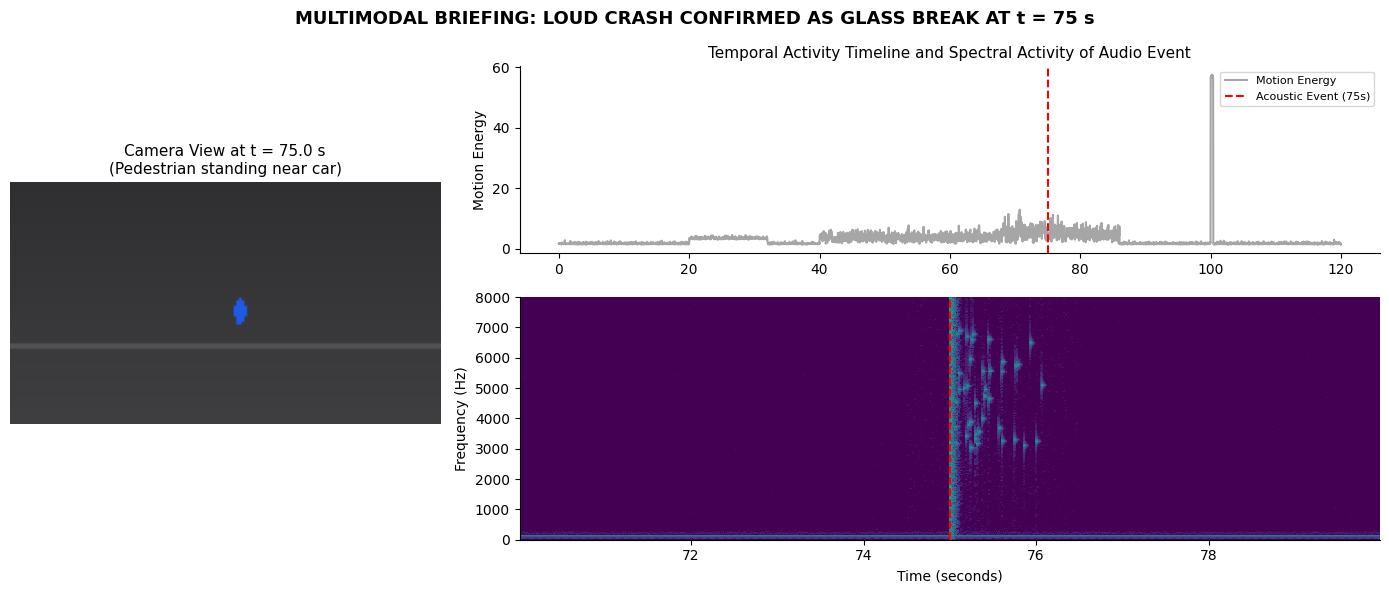

In [7]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])

# 1. Rendered frame at t = 75 s
row_75 = cctv.iloc[audio_event_idx] # t_sel corresponds to the audio event index
ax_frame = fig.add_subplot(gs[:, 0])
ax_frame.imshow(render_frame(row_75))
ax_frame.set_title(f"Camera View at t = {t_sel:.1f} s\n(Pedestrian standing near car)", fontsize=11)
ax_frame.axis("off")

# 2. Full motion + audio timeline with marker at 75 s
ax_timeline = fig.add_subplot(gs[0, 1])
ax_timeline.plot(cctv["time_s"], cctv["motion_energy"], color="gray", alpha=0.7, label="Motion Energy")
ax_timeline.axvline(t_sel, color="red", linestyle="--", linewidth=1.5, label="Acoustic Event (75s)")
ax_timeline.set_ylabel("Motion Energy")
ax_timeline.set_title("Temporal Activity Timeline and Spectral Activity of Audio Event", fontsize=11)
ax_timeline.legend(loc="upper right", fontsize=8)

# 3. Spectrogram of x_audio (70-80 s)
ax_spec = fig.add_subplot(gs[1, 1])
mask_10s = (t_audio >= 70.0) & (t_audio <= 80.0)
x_audio_10s = x_audio[mask_10s]
f, t_s, Sxx = signal.spectrogram(x_audio_10s, fs=FS, nperseg=512, noverlap=384)
Sxx_db = 10 * np.log10(Sxx + 1e-10)

# Adjust spectrogram time axis to absolute seconds (70 to 80 s)
im = ax_spec.pcolormesh(t_s + 70.0, f, Sxx_db, cmap="viridis", vmin=-80, vmax=-10)
ax_spec.axvline(t_sel, color="red", linestyle="--", linewidth=1.5)
ax_spec.set_xlabel("Time (seconds)")
ax_spec.set_ylabel("Frequency (Hz)")
ax_spec.set_ylim(0, 8000)

fig.suptitle("MULTIMODAL BRIEFING: LOUD CRASH CONFIRMED AS GLASS BREAK AT t = 75 s", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_
* **What would go wrong:** If the audio track were offset by +2 seconds, the temporal alignment of the events across modalities would break. The loud bang on the audio spectrogram would appear to happen at t = 77.0 s, whereas the video and motion tracking would show the pedestrian running away starting at t = 78.6 s. This mismatch would distort the cause-and-effect relationship of the incident, misleading analysts into thinking the running occurred almost immediately after the sound, or confusing the timeline of events completely.
* **Which panel would make it visible:** The synchronized multimodal layout on **Panel 2 (the Spectrogram on the bottom right)** plotted alongside **Panel 1 (the camera view and the motion timeline)** would make the error obvious. A viewer looking at the red marker at 75 s would see no acoustic energy spike in the spectrogram (as the spike would have shifted to 77 s), whereas the camera view and the motion timeline would show active motion changes, making the temporal misalignment instantly apparent.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_
* At t = 75.0 s, an acoustic glass break event occurred in Parking Lot B while a pedestrian was standing near a vehicle, causing the pedestrian to immediately run away at t = 78.6 s, followed by the parking lot security lights turning on at t = 100.0 s.
* To brief the executive team efficiently, we should lead with the **synchronized multimodal dashboard** first, as it links the raw structures of video and audio into an aligned temporal pattern, easily transforming raw signal changes into direct security meaning in one single-screen view.
* For storage, we recommend transitioning to a hybrid dynamic recording policy: store at 640x360 at 10 fps to save over 96% in daily storage capacity, but temporarily trigger high-definition 1080p 30 fps recording upon detecting sudden motion or acoustic alerts.
* This adaptive policy ensures we never sacrifice critical high-frequency spatial detail (like license plates or facial features) during active security anomalies.